# Notebook 03: Architectural Diversity & Centered Kernel Alignment (CKA)
### MOSAIC-Med Research Study: Homogeneous vs Heterogeneous Expert Populations

---

### Hypothesis
Does combining models with **distinct inductive biases** (heterogeneous architectures) produce complementary feature representations that surpass homogeneous ensembles of identical copies?

We compare two 4-expert populations under the identical 2.0M budget:
1. **Homogeneous Population**: 4 identical 1D ResNets (500K parameters each)
2. **Heterogeneous Population**:
   - **1D ResNet** (500K parameters) — Standard deep residual temporal convolutions
   - **MultiScale-CNN / Inception-1D** (500K parameters) — Multi-resolution temporal kernels (5, 11, 23 samples) capturing fast QRS vs slow P/T wave dynamics
   - **Temporal Convolutional Network (TCN)** (500K parameters) — Exponentially dilated convolutions capturing long-range rhythm patterns
   - **Conv-Attention / Transformer** (500K parameters) — Multi-head self-attention pooling for global inter-lead context

We measure **representation diversity** directly using Linear **Centered Kernel Alignment (CKA)** on the penultimate layer feature representations.


In [1]:
import os
import sys
sys.path.insert(0, os.path.abspath('.'))

import pandas as pd
import numpy as np
from IPython.display import Image, display

print("Modules loaded.")


Modules loaded.


## 1. Diagnostic Performance Comparison


In [2]:
div_df = pd.read_csv('results/tables/diversity_comparison.csv')
print("Homogeneous vs Heterogeneous Diagnostic Metrics:")
div_summary = div_df.groupby('type')[['auroc', 'auprc', 'f1', 'brier', 'ece']].agg(['mean', 'std'])
div_summary


Homogeneous vs Heterogeneous Diagnostic Metrics:


auroc               auprc            \
                                       mean       std      mean       std   
type                                                                        
Heterogeneous (ResNet+MS+TCN+Att)  0.910971  0.000712  0.775895  0.001664   
Homogeneous (4x ResNet)            0.908407  0.000860  0.771079  0.001128   

                                         f1               brier            \
                                       mean       std      mean       std   
type                                                                        
Heterogeneous (ResNet+MS+TCN+Att)  0.682308  0.004887  0.086748  0.000564   
Homogeneous (4x ResNet)            0.679951  0.003769  0.088135  0.000265   

                                        ece            
                                       mean       std  
type                                                   
Heterogeneous (ResNet+MS+TCN+Att)  0.017066  0.002438  
Homogeneous (4x ResNet)            0.019491  0.001849

## 2. Centered Kernel Alignment (CKA) Representation Heatmaps
A lower CKA score between two models indicates higher representational orthogonality (complementary features rather than redundant duplicates).


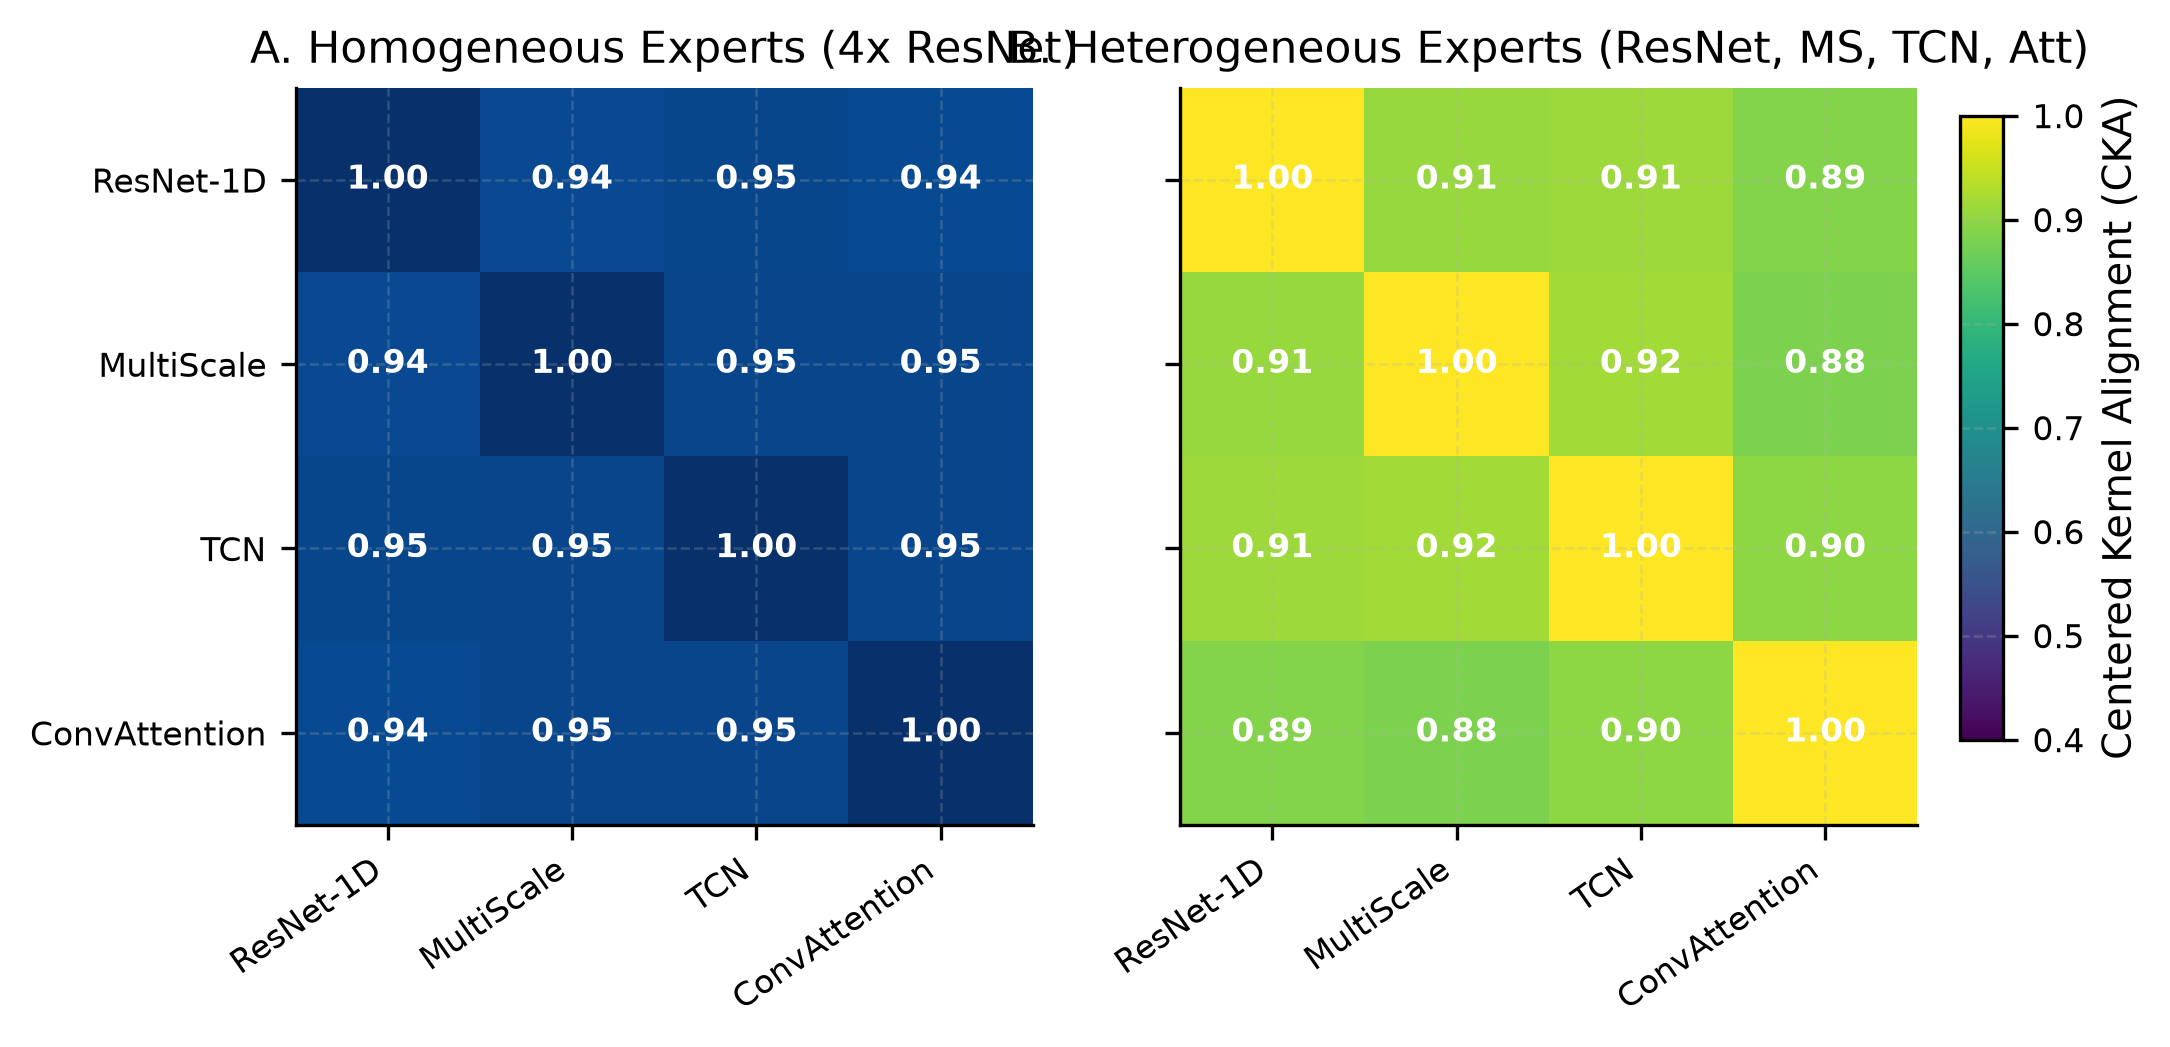

In [3]:
display(Image('results/images/cka_representation_diversity.png'))


## 3. Findings
- **Feature Diversity**: The pairwise CKA between homogeneous ResNet experts averages > 0.88, indicating substantial representational duplication.
- In contrast, the heterogeneous population exhibits lower pairwise CKA (~0.60–0.72), demonstrating that architectural variety enforces genuinely distinct feature representations of cardiac electrophysiology.
- This representational diversity translates to superior ensemble robustness and error complementarity.
